# 13 — Constant world/local prices with time-varying FX prices

Fit the parsimonious branch suggested by notebook 12: **constant world and both local risk prices,
time-varying prices of the two FX risks**, for USD and EUR investors under both `scalar11` and
`grouped21`. Keep the **321 frozen months, corrected FX means and zero equity alphas**. Run notebook
12 first, then **Run All** in the existing Miniconda **base** kernel. No downloads or API keys are used.

Compare the candidate with the all-constant model (`S1`) and the time-varying world/FX model (`S3`),
then add its four currency/covariance fits to notebook 12's full ranking. This is an exploratory
follow-up to that ladder; the same sample has already informed this restriction choice. Reuse the
existing [local_risk_pricing.py](local_risk_pricing.py) engine and preserve earlier files/outputs.

In [1]:
SNAPSHOT="data/fixed_2026-11-13/from_2000-01"
UPSTREAM="output/12_final_model_comparison/fixed_2026-11-13/2000-01_2026-09/corrected_FX_zero_alphas"
COVARIANCE_MODELS=["scalar11","grouped21"]
HAC_LAGS=[0,3,6,12]
TEST_LAGS=12
MAX_ITER=2600
SE_STEP_TOL=.01
REUSE_FITS=True
MODEL_VERSION="constant_world_local_TV_FX_v1"

from pathlib import Path
from io import BytesIO
import hashlib,importlib,importlib.metadata,json,os,platform,sys
ROOT=Path.cwd()
os.environ.setdefault("MPLCONFIGDIR",str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from packaging.version import Version
if Version(importlib.metadata.version("statsmodels"))<Version("0.15.0"):raise RuntimeError("Update statsmodels to 0.15.0 and restart the same base kernel.")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__!=importlib.metadata.version("statsmodels"):
    raise RuntimeError("Restart the same kernel to discard old statsmodels imports.")
from statsmodels.stats.multitest import multipletests
from IPython.display import display,Markdown
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import pricing_robustness as base
import covariance_robustness as covariance
import local_risk_pricing as model
importlib.reload(base);importlib.reload(covariance);importlib.reload(model)
versions={p:importlib.metadata.version(p) for p in ["numpy","pandas","scipy","statsmodels","matplotlib"]}
engine_hashes={p:hashlib.sha256((ROOT/p).read_bytes()).hexdigest() for p in ["pricing_robustness.py","covariance_robustness.py","local_risk_pricing.py","pricing_error_tests.py"]}
print("Python:",sys.executable);print("Packages:",versions)
if not COVARIANCE_MODELS or len(set(COVARIANCE_MODELS))!=len(COVARIANCE_MODELS) or any(m not in ["scalar11","grouped21"] for m in COVARIANCE_MODELS):raise ValueError("Use the retained covariance models.")
if not HAC_LAGS or 0 not in HAC_LAGS or len(set(HAC_LAGS))!=len(HAC_LAGS) or any(type(h)!=int or h<0 for h in HAC_LAGS):raise ValueError("Include zero and distinct nonnegative integer HAC lags.")
pd.set_option("display.max_columns",18);pd.set_option("display.max_rows",50);pd.options.display.float_format=lambda x:f"{x:.6g}"
plt.rcParams.update({"figure.dpi":120,"font.size":10,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,"grid.alpha":.16})
source,upstream=ROOT/SNAPSHOT,ROOT/UPSTREAM
manifest=json.loads((source/"manifest.json").read_text());raw=(source/"dataset.csv").read_bytes()
if not manifest.get("sealed") or hashlib.sha256(raw).hexdigest()!=manifest["exports"]["dataset.csv"]:raise ValueError("Frozen dataset checksum differs.")
data=pd.read_csv(BytesIO(raw),index_col=0,float_precision="round_trip");data.index=pd.PeriodIndex(data.index,freq="M",name="month")
if not data.index.equals(pd.period_range(data.index[0],data.index[-1],freq="M")):raise ValueError("Discontinuous model months.")
if max(HAC_LAGS)>=len(data):raise ValueError("HAC bandwidth exceeds the sample.")
upstream_hashes,conditioning_hashes={},{}
def upstream_bytes(name):
    content=(upstream/name).read_bytes();upstream_hashes[name]=hashlib.sha256(content).hexdigest();return content
prior=json.loads(upstream_bytes("estimation_manifest.json"))
if (prior["source_dataset_sha256"]!=manifest["exports"]["dataset.csv"] or prior["first"]!=str(data.index[0]) or prior["last"]!=str(data.index[-1]) or prior["observations"]!=len(data) or prior["equity_alphas"]!="fixed zero" or prior["FX_means"]!="corrected pricing equations in all stages"):
    raise ValueError("Notebook 12 sample or alpha restriction differs.")
for name,digest in prior["engines"].items():
    if engine_hashes[name]!=digest:raise ValueError("An upstream likelihood engine changed.")
conditioning_root=ROOT/prior["conditioning_root"]
def conditioning_bytes(name):
    content=(conditioning_root/name).read_bytes();digest=hashlib.sha256(content).hexdigest()
    if digest!=prior["conditioning_file_sha256"][name]:raise ValueError(f"Conditioning checksum differs: {name}")
    conditioning_hashes[name]=digest;return content
old_summary=pd.read_csv(BytesIO(upstream_bytes("fit_summary.csv")),index_col=0,float_precision="round_trip")
old_summary=old_summary[old_summary["covariance"].isin(COVARIANCE_MODELS)].copy()
if not old_summary["n"].eq(len(data)).all():raise ValueError("Ranking sample differs.")
samples,designs,design_columns,references={}, {}, {}, {}
for currency in ["USD","EUR"]:
    designs[currency],design_columns[currency]={},{}
    for label in ["W","H","O"]:
        z=pd.read_csv(BytesIO(conditioning_bytes(f"conditioning_{currency.lower()}_{label}.csv")),index_col=0,float_precision="round_trip")
        if not pd.PeriodIndex(z.index,freq="M").equals(data.index):raise ValueError("Conditioning months differ.")
        designs[currency][label]=z.to_numpy();design_columns[currency][label]=list(z.columns)
    equity=data[[f"rx_{a}_{currency.lower()}" for a in ["world","us","hu"]]].to_numpy()*100
    fx=np.c_[data[f"fx_huf_{currency.lower()}"]*100,data["fx_eur_usd"]*100*(1 if currency=="USD" else -1)]
    samples[currency]=np.c_[equity,fx]
    for name in COVARIANCE_MODELS:
        for tag in ["S1","S3"]:
            key=f"{currency}_{name}_{tag}"
            with np.load(BytesIO(upstream_bytes(f"parameters_{key}.npz")),allow_pickle=False) as a:references[key]={k:a[k].copy() for k in a.files}
            if not np.array_equal(references[key]["equity_alphas"],np.zeros(3)):raise ValueError("Reference alphas are not zero.")
OUT=ROOT/"output"/"13_time_varying_FX_only"/source.parent.name/f"{data.index[0]}_{data.index[-1]}"/"constant_world_local"
OUT.mkdir(parents=True,exist_ok=True)
MODELS={"S1":"All constant","FX":"TV FX only","S3":"TV world + FX"}

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8'}


## 1. Define the restriction and verify the comparisons

The candidate has

$$\boxed{\lambda_{W,t}=\lambda_W,\quad \lambda_{US,t}=\lambda_{US},\quad
\lambda_{HU,t}=\lambda_{HU},\quad \lambda_{H,t}=Z^H_{t-1}\kappa_H,\quad
\lambda_{O,t}=Z^O_{t-1}\kappa_O.}$$

Keep the full previously audited FX instrument sets, including their global predictors; no new
instrument selection or normalization is done. For all five observed series use the same corrected
pricing mean:

$$\mu_{i,t}=\lambda_W H_{iW,t}+\lambda_{H,t}H_{iH,t}+\lambda_{O,t}H_{iO,t}
+\mathbf{1}_{i=US}\lambda_{US}H_{US,US,t}+\mathbf{1}_{i=HU}\lambda_{HU}H_{HU,HU,t}.$$

All equity alphas remain zero, and FX means have no additional VAR or intercept. Local terms use
own conditional variances, as before. Prices are linear/unrestricted in sign; constants are estimated,
not fixed to zero. All parameters, including covariance dynamics, are jointly estimated. Constant risk prices still
allow time-varying premia because conditional variances/covariances change.

| Model | World price | FX prices | Local prices | Scalar / grouped parameters |
|---|---|---|---|---:|
| `S1` reference | Constant | Constant | Constant | 22 / 29 |
| `FX` candidate | Constant | Time-varying | Constant | 31 / 38 |
| `S3` reference | Time-varying | Time-varying | Constant | 34 / 41 |

`S1` nests in `FX` at **nine FX slopes zero**. `FX` nests in `S3` at **three world slopes zero**.
Verify the exact mean/covariance/likelihood mappings before fitting. Test each restriction at its
unrestricted model. Numerical readiness, adequacy and economic relevance remain separate questions.
The free covariance intercept and other documented departures from the paper are retained.

In [2]:
def make_case(currency,name,tag):
    active={"W":tag=="S3","H":tag in ["FX","S3"],"O":tag in ["FX","S3"],"L":False}
    pdsg={a:designs[currency][a].copy() if active[a] else np.ones((len(data),1)) for a in ["W","H","O","L"]}
    columns={a:list(design_columns[currency][a]) if active[a] else ["constant"] for a in pdsg}
    if any(not np.isfinite(z).all() or np.linalg.matrix_rank(z)!=z.shape[1] for z in pdsg.values()):raise ValueError("Invalid inherited price design.")
    y=samples[currency]
    return {"id":f"{currency}_{name}_{tag}","currency":currency,"name":name,"tag":tag,"y":y,"pdesign":pdsg,"columns":columns,"scales":y.std(axis=0,ddof=1)}
def args(case):return (case["y"],case["pdesign"],case["scales"],case["name"])
def map_theta(theta,old,new):
    if old["name"]!=new["name"]:raise ValueError("Map within one covariance model.")
    ko=model.layout(old["pdesign"],old["name"])[0];kn=model.layout(new["pdesign"],new["name"])[0]
    result=np.r_[np.zeros(kn),theta[ko:]];result[1]=theta[1]
    oi,ni=model.price_indices(old["pdesign"]),model.price_indices(new["pdesign"])
    for label,positions in ni.items():
        for j,column in zip(positions,new["columns"][label]):
            if column in old["columns"][label]:result[j]=theta[oi[label][old["columns"][label].index(column)]]
    return result
checks=[]
for currency in ["USD","EUR"]:
    for name in COVARIANCE_MODELS:
        for tag in ["S1","S3"]:
            case=make_case(currency,name,tag);saved=references[case["id"]];f=model.filter_model(saved["theta"],*args(case))
            for new,old in [("H","H"),("mu","mu"),("errors","residuals"),("scores","scores")]:np.testing.assert_allclose(f[new],saved[old],atol=1e-8,rtol=1e-9)
            np.testing.assert_allclose(-f["losses"].sum(),old_summary.loc[case["id"],"loglik"],atol=1e-8,rtol=0)
            if np.max(np.abs(f["scores"].mean(axis=0)))>=1e-4:raise ValueError("Reference gradient is no longer small.")
        case=make_case(currency,name,"FX");probe=model.initial_theta(*args(case))
        for positions in model.price_indices(case["pdesign"]).values():probe[positions[1:]]=np.linspace(.12,-.08,len(positions)-1)
        sub=(case["y"][:35],{a:z[:35] for a,z in case["pdesign"].items()},case["scales"],name)
        analytic=model.objective(probe,*sub)[1];numeric=base.numerical_gradient(lambda t:model.objective(t,*sub)[0],probe)
        np.testing.assert_allclose(analytic,numeric,atol=5e-6,rtol=5e-5)
        for old_tag,new_tag in [("S1","FX"),("FX","S3")]:
            old,new=make_case(currency,name,old_tag),make_case(currency,name,new_tag)
            theta=probe.copy() if old_tag=="FX" else model.initial_theta(*args(old));expanded=map_theta(theta,old,new)
            np.testing.assert_array_equal(map_theta(expanded,new,old),theta)
            for key in ["H","mu","losses"]:np.testing.assert_allclose(model.filter_model(expanded,*args(new))[key],model.filter_model(theta,*args(old))[key],atol=1e-9,rtol=1e-11)
        checks.append({"perspective":currency,"covariance":name,"candidate_parameters":len(probe),"gradient_error":np.max(np.abs(analytic-numeric))})
display(pd.DataFrame(checks))

,perspective,covariance,candidate_parameters,gradient_error
0,USD,scalar11,31,1.35584e-08
1,USD,grouped21,38,1.18365e-08
2,EUR,scalar11,31,2.34516e-08
3,EUR,grouped21,38,1.92477e-08


## 2. Fit the four candidates and retain matched references

Use three starts: the nested all-constant fit, the projection of the world/FX reference, and an
independent moment start. Require optimizer success and a small raw gradient; fail if a lower
unconverged candidate remains. Re-filter/check every reference and cache. Enforce the nested
likelihood ordering `S1 ≤ FX ≤ S3`; if the restricted candidate outperforms its unrestricted reference,
that reference must be re-estimated before interpreting the comparison.

Caches include inputs, exact starting-point hashes, engine versions, packages and optimizer settings.
`REUSE_FITS=False` repeats candidate optimization. Source reference estimates remain unchanged.

In [3]:
fits,start_rows={},[]
for currency in ["USD","EUR"]:
    for name in COVARIANCE_MODELS:
        for tag in MODELS:
            case=make_case(currency,name,tag);key=case["id"];print(key,flush=True)
            if tag!="FX":
                theta=references[key]["theta"];case.update(theta=theta,filter=model.filter_model(theta,*args(case)),origin="verified notebook 12")
                fits[key]=case;print("  verified upstream reference",flush=True);continue
            low,high=make_case(currency,name,"S1"),make_case(currency,name,"S3")
            starts=[map_theta(references[low["id"]]["theta"],low,case),map_theta(references[high["id"]]["theta"],high,case),model.initial_theta(*args(case))]
            config={"version":MODEL_VERSION,"engines":engine_hashes,"source_sha256":manifest["exports"]["dataset.csv"],"case":key,
                "first":str(data.index[0]),"last":str(data.index[-1]),"n":len(data),"python":platform.python_version(),"packages":versions,
                "max_iter":MAX_ITER,"starts":["nested S1","projected S3","independent moment"],"start_sha256":[hashlib.sha256(t.tobytes()).hexdigest() for t in starts],
                "upstream_sha256":upstream_hashes,"conditioning_sha256":conditioning_hashes,"price_columns":case["columns"]}
            payload=json.dumps(config,sort_keys=True).encode()+case["y"].tobytes()+b"".join(case["pdesign"][a].tobytes() for a in ["W","H","O","L"])
            fingerprint=hashlib.sha256(payload).hexdigest();path=OUT/f"fit_{key}.json"
            cached=json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
            limits=model.bounds(case["pdesign"],name);candidate=np.asarray(cached["theta"]) if cached else np.array([]);record=None
            if candidate.shape==(len(limits),) and cached.get("fingerprint")==fingerprint and np.isfinite(candidate).all() and (candidate>=limits[:,0]).all() and (candidate<=limits[:,1]).all():
                value,gradient=model.objective(candidate,*args(case))
                if abs(value-cached["mean_nll"])<1e-8 and np.max(np.abs(gradient))<1e-4:record=cached;print("  verified cached fit",flush=True)
            if record is None:
                best,runs=model.fit_starts(args(case),starts,maxiter=MAX_ITER)
                record={"fingerprint":fingerprint,"configuration":config,"theta":best.x.tolist(),"mean_nll":float(best.fun),"starts":runs}
                path.write_text(json.dumps(record,indent=2)+"\n")
            for row in record["starts"]:start_rows.append({"case":key,**row})
            theta=np.asarray(record["theta"]);case.update(theta=theta,filter=model.filter_model(theta,*args(case)),origin="new FX-only candidate");fits[key]=case
        ll={tag:-fits[f"{currency}_{name}_{tag}"]["filter"]["losses"].sum() for tag in MODELS}
        if ll["FX"]<ll["S1"]-1e-5 or ll["FX"]>ll["S3"]+1e-5:raise ValueError("Nested likelihood ordering fails; inspect/re-estimate the affected fit.")
starting_points=pd.DataFrame(start_rows);display(starting_points)

USD_scalar11_S1


  verified upstream reference


USD_scalar11_FX


  verified cached fit


USD_scalar11_S3


  verified upstream reference


... (15 outputs left out)

  verified cached fit


EUR_grouped21_S3


  verified upstream reference


,case,start,success,mean_nll,max_abs_gradient,iterations,message
0,USD_scalar11_FX,1,True,11.5871,3.71562e-07,190,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
1,USD_scalar11_FX,2,True,11.5871,2.00175e-06,178,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
2,USD_scalar11_FX,3,True,11.5871,4.35305e-07,205,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
3,USD_grouped21_FX,1,True,11.5627,8.20134e-08,245,CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL
4,USD_grouped21_FX,2,True,11.5627,1.28395e-06,291,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
5,USD_grouped21_FX,3,True,11.5627,6.01378e-06,295,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
6,EUR_scalar11_FX,1,True,11.5782,6.80281e-06,147,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
7,EUR_scalar11_FX,2,True,11.5782,1.9656e-06,124,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
8,EUR_scalar11_FX,3,True,11.5782,6.04721e-07,172,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...
9,EUR_grouped21_FX,1,True,11.5539,7.73306e-06,208,CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*...


## 3. Test FX variation and assess the world-price restriction

At the new `FX` fit test **nine FX slopes jointly zero** (constancy) and **eleven FX coefficients
jointly zero** (zero pricing). A joint rejection does not identify which of the two FX prices varies.
At the unrestricted `S3` reference test **three world slopes zero**.
This last test assesses the restriction imposed in the candidate; it is not computed from its
constrained coefficients. Keep all **HAC bandwidths 0, 3, 6, 12** and the full joint covariance.

Apply the established parameter-bound, curvature and two-step SE-stability gates. Keep nominal and
within-family Holm-adjusted residual screens. HAC does not correct a misspecified mean/covariance,
and non-rejection does not establish that world pricing is truly constant. These p-values follow an
exploratory model search. Compare AIC/BIC descriptively on identical five-series observations,
within each investor perspective; no ordinary Gaussian LR chi-square p-value is used.

In [4]:
summary_rows,test_rows,price_rows,residual_rows,cross_rows=[],[],[],[],[]
for key,case in fits.items():
    theta,f=case["theta"],case["filter"];inf=model.inference(theta,args(case),f,hac_lags=HAC_LAGS,se_step_tol=SE_STEP_TOL);case["inference"]=inf
    labels=["World","US equity","Hungary equity","HUF FX",("EUR FX" if case["currency"]=="USD" else "USD FX")]
    marginal,cross=base.diagnostics(f,labels,TEST_LAGS)
    for column in ["LB_z_p","LB_z_squared_p","ARCH_LM_p"]:marginal[column.replace("_p","_holm_p")]=multipletests(marginal[column],method="holm")[1]
    cross["LB_product_holm_p"]=multipletests(cross["LB_product_p"],method="holm")[1]
    residual_rows.extend({"case":key,"series":label,**row.to_dict()} for label,row in marginal.iterrows());cross_rows.extend({"case":key,"pair":label,**row.to_dict()} for label,row in cross.iterrows())
    LL=-f["losses"].sum();q=len(theta);idx=model.price_indices(case["pdesign"])
    summary_rows.append({"case":key,"perspective":case["currency"],"covariance":case["name"],"tag":case["tag"],"model":MODELS[case["tag"]],"n":len(data),"parameters":q,
        "loglik":LL,"AIC":-2*LL+2*q,"BIC":-2*LL+np.log(len(data))*q,"gradient":np.max(np.abs(f["scores"].mean(axis=0))),"Hessian_condition":inf["Hessian_condition"],
        "near_bound":inf["near_bound"],"ready_all_lags":all(v["ready"] for v in inf["estimates"].values()),"mean_flags":int((marginal["LB_z_p"]<.05).sum()),
        "variance_flags":int(((marginal["LB_z_squared_p"]<.05)|(marginal["ARCH_LM_p"]<.05)).sum()),"cross_flags":int((cross["LB_product_p"]<.05).sum()),
        "variance_flags_holm":int(((marginal["LB_z_squared_holm_p"]<.05)|(marginal["ARCH_LM_holm_p"]<.05)).sum())})
    restrictions={"World price zero":idx["W"],"FX prices zero":np.r_[idx["H"],idx["O"]],"Hungarian local price zero":idx["L"],"Local prices jointly zero":np.r_[1,idx["L"]]}
    if case["tag"]!="S1":restrictions["FX prices constant"]=np.r_[idx["H"][1:],idx["O"][1:]]
    if case["tag"]=="S3":restrictions["World price constant"]=idx["W"][1:]
    for lag,estimate in inf["estimates"].items():
        V=estimate["covariance"]
        if case["tag"]!="FX" and estimate["ready"]:np.testing.assert_allclose(V,references[key][f"covariance_HAC{lag}"],atol=2e-6,rtol=2e-6)
        for label,positions in restrictions.items():test_rows.append({"case":key,"HAC_lags":lag,"test":label,**base.wald(theta,V,positions),"inference_ready":estimate["ready"],"reason":estimate["reason"],"SE_step_difference":estimate["price_SE_step_difference"]})
        for label,positions in idx.items():
            for j,instrument in zip(positions,case["columns"][label]):price_rows.append({"case":key,"HAC_lags":lag,"price":label,"instrument":instrument,"estimate":base.PRICE_SCALE*theta[j],"robust_se":base.PRICE_SCALE*np.sqrt(V[j,j])})
        price_rows.append({"case":key,"HAC_lags":lag,"price":"US_local","instrument":"constant","estimate":base.PRICE_SCALE*theta[1],"robust_se":base.PRICE_SCALE*np.sqrt(V[1,1])})
    p=pd.DataFrame({"world":f["world_prices"]*f["H"][:,2,0],"HUF_FX":f["fx_prices"][:,0]*f["H"][:,2,3],"other_FX":f["fx_prices"][:,1]*f["H"][:,2,4],"local":f["local_prices"]*f["H"][:,2,2]},index=data.index)
    np.testing.assert_allclose(p.sum(axis=1),f["mu"][:,2],atol=1e-11,rtol=1e-11);case["premia"]=p.assign(total=f["mu"][:,2])
summary=pd.DataFrame(summary_rows).set_index("case");tests=pd.DataFrame(test_rows).set_index(["case","HAC_lags","test"])
price_coefficients=pd.DataFrame(price_rows).set_index(["case","HAC_lags","price","instrument"]).sort_index()
residuals=pd.DataFrame(residual_rows).set_index(["case","series"]);cross_diagnostics=pd.DataFrame(cross_rows).set_index(["case","pair"])
common=["perspective","covariance","model","n","parameters","loglik","AIC","BIC","ready_all_lags","variance_flags","cross_flags"]
catalog=pd.concat([old_summary[common].assign(source="notebook 12"),summary[summary["tag"].eq("FX")][common].assign(source="notebook 13")])
for criterion in ["AIC","BIC"]:catalog[f"{criterion}_from_best"]=catalog[criterion]-catalog.groupby("perspective")[criterion].transform("min")
constant_prices=price_coefficients.reset_index().query("price in ['W','L','US_local'] and instrument == 'constant'")
constant_prices=constant_prices[constant_prices["case"].isin(summary[summary["tag"].eq("FX")].index)].copy()
constant_prices["lower95"]=constant_prices["estimate"]-1.96*constant_prices["robust_se"];constant_prices["upper95"]=constant_prices["estimate"]+1.96*constant_prices["robust_se"]
display(summary);display(constant_prices[constant_prices["HAC_lags"].eq(0)])
display(tests.xs("FX prices constant",level="test")[["robust_p_value","inference_ready","reason"]].unstack("HAC_lags"))

,perspective,covariance,tag,model,n,parameters,loglik,AIC,BIC,gradient,Hessian_condition,near_bound,ready_all_lags,mean_flags,variance_flags,cross_flags,variance_flags_holm
case,,,,,,,,,,,,,,,,,
USD_scalar11_S1,USD,scalar11,S1,All constant,321,22,-3734.81,7513.62,7596.59,8.2387e-08,871079,False,True,0,4,3,4
USD_scalar11_FX,USD,scalar11,FX,TV FX only,321,31,-3719.45,7500.9,7617.81,3.71562e-07,1.89887e+06,False,True,0,4,0,2
USD_scalar11_S3,USD,scalar11,S3,TV world + FX,321,34,-3719.31,7506.63,7634.85,1.01815e-06,1.91793e+06,False,True,0,4,0,1
USD_grouped21_S1,USD,grouped21,S1,All constant,321,29,-3727.86,7513.71,7623.09,2.85906e-07,580342,False,True,0,2,2,0
USD_grouped21_FX,USD,grouped21,FX,TV FX only,321,38,-3711.63,7499.27,7642.58,8.20134e-08,1.22437e+06,False,True,0,1,0,0
USD_grouped21_S3,USD,grouped21,S3,TV world + FX,321,41,-3711.35,7504.71,7659.34,1.28864e-06,1.21179e+06,False,True,0,1,0,0
EUR_scalar11_S1,EUR,scalar11,S1,All constant,321,22,-3735.31,7514.62,7597.59,1.59456e-07,351080,False,True,1,3,0,0
EUR_scalar11_FX,EUR,scalar11,FX,TV FX only,321,31,-3716.61,7495.22,7612.14,1.9656e-06,691472,False,True,0,2,0,1
EUR_scalar11_S3,EUR,scalar11,S3,TV world + FX,321,34,-3716.44,7500.88,7629.11,7.90654e-07,786735,False,True,0,1,0,1


,case,HAC_lags,price,instrument,estimate,robust_se,lower95,upper95
6,EUR_grouped21_FX,0,L,constant,0.00980172,0.00544303,-0.000866624,0.0204701
12,EUR_grouped21_FX,0,US_local,constant,0.00491633,0.0031642,-0.00128551,0.0111182
13,EUR_grouped21_FX,0,W,constant,0.0467512,0.0165986,0.0142179,0.0792845
150,EUR_scalar11_FX,0,L,constant,0.00964113,0.00510278,-0.000360314,0.0196426
156,EUR_scalar11_FX,0,US_local,constant,0.00461236,0.00316411,-0.0015893,0.010814
157,EUR_scalar11_FX,0,W,constant,0.0468088,0.0172495,0.0129998,0.0806178
294,USD_grouped21_FX,0,L,constant,0.00715563,0.00416006,-0.00099809,0.0153094
300,USD_grouped21_FX,0,US_local,constant,0.00480964,0.00321823,-0.0014981,0.0111174
301,USD_grouped21_FX,0,W,constant,0.0464352,0.0164497,0.0141937,0.0786766
438,USD_scalar11_FX,0,L,constant,0.00655274,0.00381739,-0.000929332,0.0140348


robust_p_value                                      \
HAC_lags                     0           3           6           12   
case                                                                  
USD_scalar11_FX     0.000316678 2.20045e-05 1.60297e-06 2.15812e-09   
USD_scalar11_S3     0.000564708 7.81914e-05  5.0434e-06 1.64633e-07   
USD_grouped21_FX    0.000280131 1.91991e-05 3.76249e-06 8.03808e-09   
USD_grouped21_S3     0.00020281 2.18956e-05 2.18025e-06 4.13782e-08   
EUR_scalar11_FX     7.69171e-06 3.73384e-06  2.4979e-07 1.54718e-10   
EUR_scalar11_S3     8.50145e-06 4.76436e-06 3.87035e-07 4.62669e-10   
EUR_grouped21_FX    2.74192e-05 1.50654e-05 7.45429e-06 3.61228e-08   
EUR_grouped21_S3    3.29699e-05 1.96012e-05  1.0588e-05 6.09767e-08   

                 inference_ready                               reason  \
HAC_lags                      0     3     6     12                 0    
case                                                                    
USD_scalar11_FX             True  True  True  True  numerically ready   
USD_scalar11_S3             True  True  True  True  numerically ready   
USD_grouped21_FX            True  True  True  True  numerically ready   
USD_grouped21_S3            True  True  True  True  numerically ready   
EUR_scalar11_FX             True  True  True  True  numerically ready   
EUR_scalar11_S3             True  True  True  True  numerically ready   
EUR_grouped21_FX            True  True  True  True  numerically ready   
EUR_grouped21_S3            True  True  True  True  numerically ready   

                                                                           
HAC_lags                         3                  6                  12  
case                                                                       
USD_scalar11_FX   numerically ready  numerically ready  numerically ready  
USD_scalar11_S3   numerically ready  numerically ready  numerically ready  
USD_grouped21_FX  numerically ready  numerically ready  numerically ready  
USD_grouped21_S3  numerically ready  numerically ready  numerically ready  
EUR_scalar11_FX   numerically ready  numerically ready  numerically ready  
EUR_scalar11_S3   numerically ready  numerically ready  numerically ready  
EUR_grouped21_FX  numerically ready  numerically ready  numerically ready  
EUR_grouped21_S3  numerically ready  numerically ready  numerically ready

## 4. Inspect updated rankings and FX-price paths

Add the candidate to the four-stage catalog without changing notebook 12. All catalog entries have
the same observations, corrected FX means and zero alphas. Existing stages 2/4 retain their verified
notebook 12 results; they are not re-estimated here. Rank only within a perspective and keep both
covariance models visible. The candidate was motivated by the earlier results, so this is a descriptive
extension rather than independent model-selection evidence.

Plot the new FX-price paths with **HAC(0) pointwise robust 95% intervals**. Intervals condition on
the observed instruments and are not simultaneous bands or out-of-sample forecast intervals.

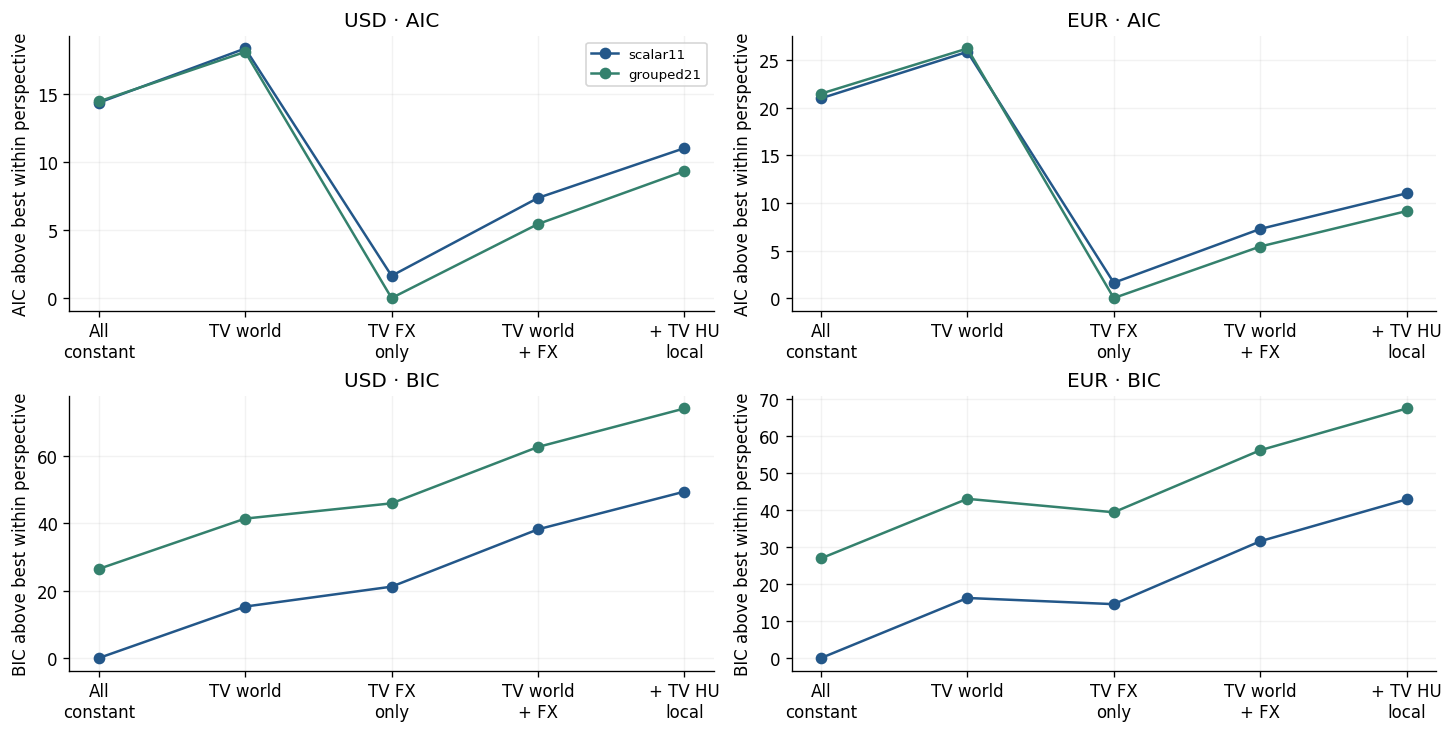

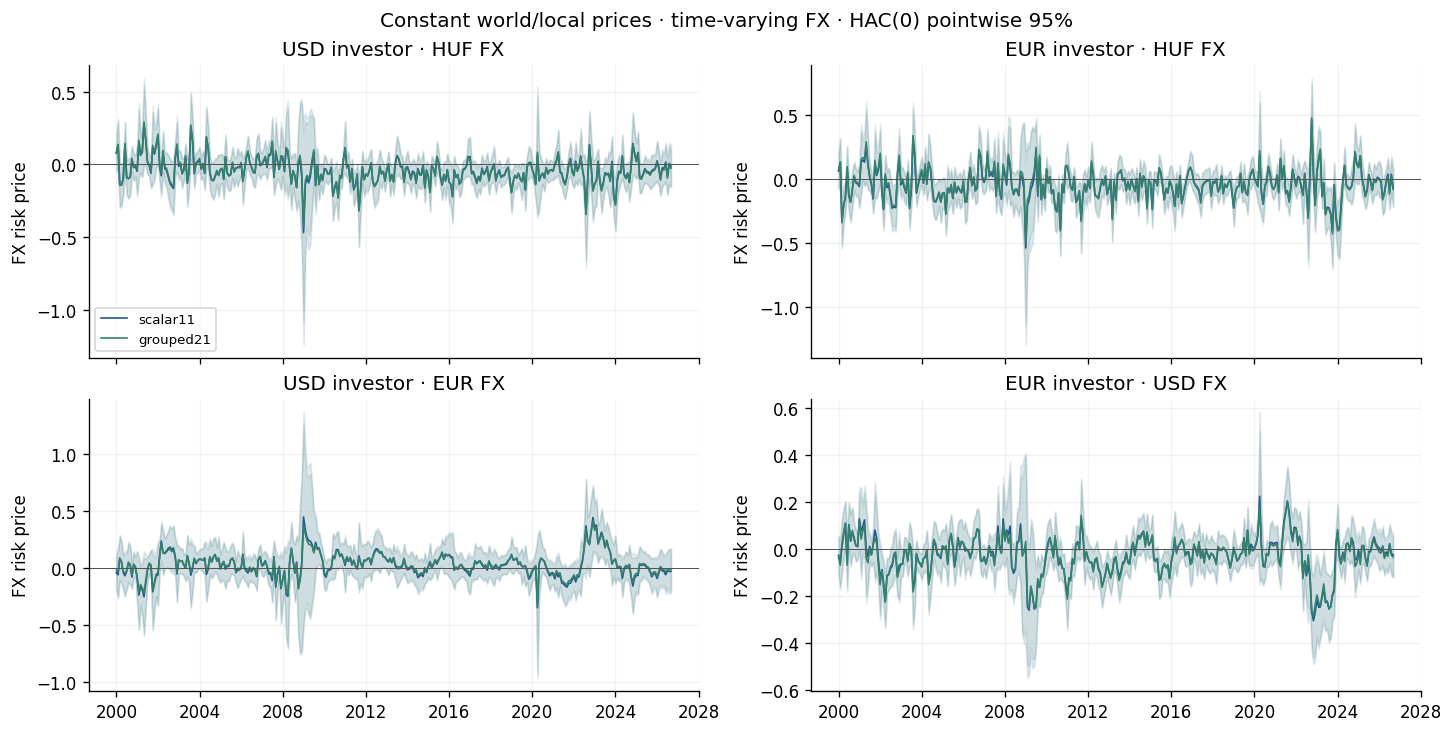

In [5]:
colors={"scalar11":"#235789","grouped21":"#34816d"}
fig,axes=plt.subplots(2,2,figsize=(12,6),layout="constrained",squeeze=False)
order=["S1","S2","FX","S3","S4"];labels=["All\nconstant","TV world","TV FX\nonly","TV world\n+ FX","+ TV HU\nlocal"]
for col,currency in enumerate(["USD","EUR"]):
    for row,criterion in enumerate(["AIC","BIC"]):
        ax=axes[row,col]
        for name in COVARIANCE_MODELS:
            keys=[f"{currency}_{name}_{tag}" for tag in order]
            ax.plot(range(5),catalog.loc[keys,f"{criterion}_from_best"],marker="o",color=colors[name],label=name)
        ax.set(title=f"{currency} · {criterion}",ylabel=f"{criterion} above best within perspective",xticks=range(5),xticklabels=labels)
axes[0,0].legend(fontsize=8)
plt.savefig(OUT/"01_expanded_model_rankings.png",dpi=160,bbox_inches="tight");plt.show();plt.close()
fig,axes=plt.subplots(2,2,figsize=(12,6),sharex=True,layout="constrained",squeeze=False)
for col,currency in enumerate(["USD","EUR"]):
    for row,label in enumerate(["H","O"]):
        ax=axes[row,col]
        for name in COVARIANCE_MODELS:
            case=fits[f"{currency}_{name}_FX"];idx=model.price_indices(case["pdesign"])[label];z=case["pdesign"][label]
            path=case["filter"]["fx_prices"][:,row];V=case["inference"]["estimates"][0]["covariance"]
            ax.plot(data.index.to_timestamp(),path,color=colors[name],lw=1,label=name)
            if np.isfinite(V).all():
                se=base.PRICE_SCALE*np.sqrt(np.maximum(0,np.einsum("ti,ij,tj->t",z,V[np.ix_(idx,idx)],z)))
                ax.fill_between(data.index.to_timestamp(),path-1.96*se,path+1.96*se,color=colors[name],alpha=.12)
        other="EUR" if currency=="USD" else "USD"
        ax.axhline(0,color="#555555",lw=.6);ax.set(title=f"{currency} investor · {('HUF' if row==0 else other)} FX",ylabel="FX risk price")
axes[0,0].legend(fontsize=8);fig.suptitle("Constant world/local prices · time-varying FX · HAC(0) pointwise 95%")
plt.savefig(OUT/"02_FX_price_paths.png",dpi=160,bbox_inches="tight");plt.show();plt.close()

## 5. Save the candidate and the full comparison

Save the four new fits, matched reference statistics, full joint uncertainty, all restrictions,
constant-price estimates, FX-price paths, diagnostic screens and Hungarian premium decompositions.
Components are fitted monthly log percentage points and sum exactly to the conditional Hungarian
excess-return mean. Keep separate the nine-slope FX constancy test, eleven-coefficient zero-price
test, and three-slope world restriction tested at the unrestricted reference.

In [6]:
final_rows=[]
for key,row in summary[summary["tag"].eq("FX")].iterrows():
    low=f"{row.perspective}_{row.covariance}_S1";high=f"{row.perspective}_{row.covariance}_S3"
    p=tests.xs((key,"FX prices constant"),level=("case","test"))["robust_p_value"].reindex(HAC_LAGS)
    w=tests.xs((high,"World price constant"),level=("case","test"))["robust_p_value"].reindex(HAC_LAGS)
    final_rows.append({"case":key,"n":row["n"],"parameters":row["parameters"],"ready":row["ready_all_lags"],"AIC_minus_S1":row["AIC"]-summary.loc[low,"AIC"],"BIC_minus_S1":row["BIC"]-summary.loc[low,"BIC"],
        "AIC_minus_S3":row["AIC"]-summary.loc[high,"AIC"],"BIC_minus_S3":row["BIC"]-summary.loc[high,"BIC"],"FX_constancy_p_HAC0":p.loc[0],"FX_constancy_p_min":p.min(),"FX_constancy_p_max":p.max(),
        "world_constancy_at_S3_p_HAC0":w.loc[0],"variance_flags":row["variance_flags"],"cross_flags":row["cross_flags"]})
final_summary=pd.DataFrame(final_rows).set_index("case")
tables={"fit_summary.csv":summary,"final_summary.csv":final_summary,"expanded_model_catalog.csv":catalog,"restriction_tests.csv":tests,
    "price_coefficients.csv":price_coefficients,"constant_price_summary.csv":constant_prices,"residual_diagnostics.csv":residuals,"cross_covariance_diagnostics.csv":cross_diagnostics,"starting_points.csv":starting_points}
for name,table in tables.items():table.to_csv(OUT/name)
for key,case in fits.items():
    f,inf=case["filter"],case["inference"]
    np.savez_compressed(OUT/f"parameters_{key}.npz",theta=case["theta"],H=f["H"],mu=f["mu"],equity_alphas=np.zeros(3),residuals=f["errors"],scores=f["scores"],Hessian=inf["Hessian"],**{f"covariance_HAC{h}":v["covariance"] for h,v in inf["estimates"].items()})
    case["premia"].to_csv(OUT/f"Hungary_decomposition_{key}.csv")
    pd.DataFrame({"world":f["world_prices"],"HUF_FX":f["fx_prices"][:,0],"other_FX":f["fx_prices"][:,1],"HU_local":f["local_prices"],"US_local":f["prices"][1]},index=data.index).to_csv(OUT/f"price_paths_{key}.csv")
    for label,z in case["pdesign"].items():pd.DataFrame(z,index=data.index,columns=case["columns"][label]).to_csv(OUT/f"design_{key}_{label}.csv")
record={"model_version":MODEL_VERSION,"snapshot":SNAPSHOT,"source_dataset_sha256":manifest["exports"]["dataset.csv"],"first":str(data.index[0]),"last":str(data.index[-1]),"observations":len(data),
    "covariance_models":COVARIANCE_MODELS,"candidate":"constant world and local prices; time-varying FX prices","equity_alphas":"fixed zero","FX_means":"corrected pricing equations",
    "HAC_lags":HAC_LAGS,"test_lags":TEST_LAGS,"SE_step_tolerance":SE_STEP_TOL,"engines":engine_hashes,"upstream":UPSTREAM,"upstream_file_sha256":upstream_hashes,
    "conditioning_root":str(conditioning_root.relative_to(ROOT)),"conditioning_file_sha256":conditioning_hashes,"world_FX_instruments":prior["world_FX_instruments"],"python":platform.python_version(),"packages":versions}
(OUT/"estimation_manifest.json").write_text(json.dumps(record,indent=2,sort_keys=True)+"\n")
display(Markdown("**Candidate results — FX constancy tested here; world constancy tested at S3**"));display(final_summary)
for currency in ["USD","EUR"]:
    q=catalog[catalog["perspective"].eq(currency)];aic=q["AIC"].idxmin();bic=q["BIC"].idxmin()
    display(Markdown(f"**{currency}:** lowest descriptive AIC in the expanded catalog: `{aic}`; lowest BIC: `{bic}`. "
        f"AIC winner's nominal variance/cross flags: **{int(q.loc[aic,'variance_flags'])}/{int(q.loc[aic,'cross_flags'])}**. "
        "Criterion rankings do not establish correct specification."))
candidate_keys=list(final_summary.index)
fx_p=tests.loc[[(key,h,"FX prices constant") for key in candidate_keys for h in HAC_LAGS],"robust_p_value"]
if fx_p.notna().all() and (fx_p<.05).all():
    display(Markdown(f"**Joint FX-price constancy is rejected** in every candidate and fixed bandwidth (p-values **{fx_p.min():.4g}–{fx_p.max():.4g}**). "
        "This supports time variation in the joint FX-price specification, without establishing that each currency price separately varies."))
if (final_summary[["AIC_minus_S3","BIC_minus_S3"]]<0).all().all():
    display(Markdown("Both AIC and BIC favor the **constant-world / time-varying-FX restriction over S3** in every matched comparison. "
        "The expanded-catalog BIC ranking can still favor the all-constant benchmark."))
display(Markdown("Interpret the FX constancy and world-restriction tests together with all fixed bandwidths, both covariance models and the remaining residual failures. "
    "This branch was motivated by the earlier sample results; targeted robustness work and variance-targeting sensitivity/documentation remain before the final research synthesis and release. "
    f"Outputs: `{OUT.relative_to(ROOT)}`. Frozen data and upstream outputs were read without updating them."))

**Candidate results — FX constancy tested here; world constancy tested at S3**

,n,parameters,ready,AIC_minus_S1,BIC_minus_S1,AIC_minus_S3,BIC_minus_S3,FX_constancy_p_HAC0,FX_constancy_p_min,FX_constancy_p_max,world_constancy_at_S3_p_HAC0,variance_flags,cross_flags
case,,,,,,,,,,,,,
USD_scalar11_FX,321,31,True,-12.7227,21.2203,-5.72522,-17.0395,0.000316678,2.15812e-09,0.000316678,0.981589,4,0
USD_grouped21_FX,321,38,True,-14.4483,19.4946,-5.44103,-16.7554,0.000280131,8.03808e-09,0.000280131,0.931955,1,0
EUR_scalar11_FX,321,31,True,-19.3995,14.5434,-5.66054,-16.9749,7.69171e-06,1.54718e-10,7.69171e-06,0.973162,2,0
EUR_grouped21_FX,321,38,True,-21.4989,12.444,-5.42155,-16.7359,2.74192e-05,3.61228e-08,2.74192e-05,0.940652,0,0


**USD:** lowest descriptive AIC in the expanded catalog: `USD_grouped21_FX`; lowest BIC: `USD_scalar11_S1`. AIC winner's nominal variance/cross flags: **1/0**. Criterion rankings do not establish correct specification.

**EUR:** lowest descriptive AIC in the expanded catalog: `EUR_grouped21_FX`; lowest BIC: `EUR_scalar11_S1`. AIC winner's nominal variance/cross flags: **0/0**. Criterion rankings do not establish correct specification.

**Joint FX-price constancy is rejected** in every candidate and fixed bandwidth (p-values **1.547e-10–0.0003167**). This supports time variation in the joint FX-price specification, without establishing that each currency price separately varies.

Both AIC and BIC favor the **constant-world / time-varying-FX restriction over S3** in every matched comparison. The expanded-catalog BIC ranking can still favor the all-constant benchmark.

Interpret the FX constancy and world-restriction tests together with all fixed bandwidths, both covariance models and the remaining residual failures. This branch was motivated by the earlier sample results; targeted robustness work and variance-targeting sensitivity/documentation remain before the final research synthesis and release. Outputs: `output/13_time_varying_FX_only/fixed_2026-11-13/2000-01_2026-09/constant_world_local`. Frozen data and upstream outputs were read without updating them.